# ACNE04 Severity Grading: an experiment

- **Data:** `Layered-Labs/ACNE04`

## 1. Setup and Helpers

### env setup and import necesaary lib
assumed you have most of this already installed

In [1]:
import os
from pathlib import Path

# download and cache
WORK_DIR = Path("/content") if Path("/content").exists() else Path.cwd()
HF_CACHE_DIR = WORK_DIR / "hf_cache"
os.environ["HF_HUB_CACHE"] = str(HF_CACHE_DIR / "hub")
os.environ["HF_DATASETS_CACHE"] = str(HF_CACHE_DIR / "datasets")

import hashlib
import io
import json
import shutil
import time
from concurrent.futures import ThreadPoolExecutor
from dataclasses import asdict, dataclass
from datetime import datetime
from typing import Callable

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import Image as HFImage
from datasets import load_dataset
from IPython.display import display
from PIL import Image, ImageOps
from skimage.color import rgb2gray, rgb2hsv
from skimage.feature import hog, local_binary_pattern
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from tqdm.auto import tqdm

SEED = 42
CLASS_NAMES = ["mild", "moderate", "severe", "very_severe"]
LABELS = list(range(len(CLASS_NAMES)))
N_FOLDS = 5
FOLD_COLS = [f"fold_{k}_split" for k in range(N_FOLDS)]
BASE_SIZE = 256
PAD_COLOR = (128, 128, 128)

DECODED_PATH = WORK_DIR / "acne04_decoded.npz"
IMAGES_DIR = WORK_DIR / "images"
CLEAN_PATH = WORK_DIR / "acne04_clean.npz"
RESULTS_DIR = WORK_DIR / "results"
EXPORT_DIR = WORK_DIR / "exports"

### lil helpers
some necessary helper like rotation fix, img has compute, data class, metric, grid

In [2]:
def upright(img):
    """Apply EXIF orientation and convert to RGB."""
    return ImageOps.exif_transpose(img).convert("RGB")


def pixel_hash(img):
    return hashlib.sha256(f"{img.size}".encode() + img.tobytes()).hexdigest()


def letterbox(img, size=BASE_SIZE):
    """Resize keeping aspect ratio, pad to a square. Returns the array and the content box (x0, y0, x1, y1)."""
    scale = size / max(img.size)
    new_w, new_h = max(1, round(img.width * scale)), max(1, round(img.height * scale))
    resized = img.resize((new_w, new_h), Image.Resampling.LANCZOS)
    canvas = Image.new("RGB", (size, size), PAD_COLOR)
    x0, y0 = (size - new_w) // 2, (size - new_h) // 2
    canvas.paste(resized, (x0, y0))
    return np.asarray(canvas), (x0, y0, x0 + new_w, y0 + new_h)


@dataclass
class Data:
    key: str | None
    images: np.ndarray
    boxes: np.ndarray
    y: np.ndarray
    meta: pd.DataFrame
    is_test: np.ndarray

    def fold(self, k):
        return np.flatnonzero(~self.is_test[:, k]), np.flatnonzero(self.is_test[:, k])


def metrics(y_true, y_pred):
    recall = recall_score(y_true, y_pred, labels=LABELS, average=None, zero_division=0)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "qwk": cohen_kappa_score(y_true, y_pred, labels=LABELS, weights="quadratic"),
        "mae": float(np.abs(np.asarray(y_true) - np.asarray(y_pred)).mean()),
        **{f"recall_{name}": r for name, r in zip(CLASS_NAMES, recall)},
    }


def show_grid(images, titles, ncols=4, size=2.6):
    nrows = int(np.ceil(len(images) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, img, title in zip(axes.flat, images, titles):
        ax.imshow(img)
        ax.set_title(title, fontsize=8)
    plt.tight_layout()
    plt.show()

## 2. Dataset and EDA

In [3]:
ds = load_dataset("Layered-Labs/ACNE04", split="train")
META = ds.select_columns(["file_name", "level", "severity", "lesion_count_label", "split", *FOLD_COLS]).to_pandas()
print(len(META), "images")
display(META.head())

README.md:   0%|          | 0.00/8.60k [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  415MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  410MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  305MB            

data/train-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1457 [00:00<?, ? examples/s]

1457 images


,file_name,level,severity,lesion_count_label,split,fold_0_split,fold_1_split,fold_2_split,fold_3_split,fold_4_split
0,levle0_0.jpg,0,mild,3,train,train,train,train,test,train
1,levle0_1.jpg,0,mild,3,train,train,train,test,train,train
2,levle0_10.jpg,1,moderate,20,train,train,train,train,test,train
3,levle0_100.jpg,0,mild,2,train,train,train,train,train,test
4,levle0_101.jpg,0,mild,1,train,train,train,train,test,train


### Labels and Folds

In [4]:
display(META["severity"].value_counts().reindex(CLASS_NAMES).to_frame("images"))

test_counts = (META[FOLD_COLS] == "test").sum(axis=1)
print("Times each image is in a test fold:", test_counts.value_counts().to_dict())
print("Share of rows where `split` equals each fold column:",
      {c: round(float((META["split"] == META[c]).mean()), 3) for c in FOLD_COLS})

display(pd.DataFrame({
    c: META.loc[META[c] == "test", "severity"].value_counts() for c in FOLD_COLS
}).reindex(CLASS_NAMES).rename_axis("test images per fold"))

,images
severity,
mild,513
moderate,633
severe,182
very_severe,129


Times each image is in a test fold: {1: 1450, 2: 5, 0: 2}
Share of rows where `split` equals each fold column: {'fold_0_split': 1.0, 'fold_1_split': 0.599, 'fold_2_split': 0.599, 'fold_3_split': 0.599, 'fold_4_split': 0.599}


,fold_0_split,fold_1_split,fold_2_split,fold_3_split,fold_4_split
test images per fold,,,,,
mild,103,103,103,103,103
moderate,127,127,127,127,127
severe,36,36,36,36,36
very_severe,26,26,26,26,26


### stats of lesion per class, also is filename prefix the grrade also?

In [5]:
display(META.groupby("severity")["lesion_count_label"].agg(["min", "max", "median"]).reindex(CLASS_NAMES))
display(pd.crosstab(META["file_name"].str.extract(r"^(levle\d)")[0].rename("prefix"), META["severity"])[CLASS_NAMES])

,min,max,median
severity,,,
mild,1,5,2.0
moderate,6,20,8.0
severe,21,42,25.0
very_severe,51,65,58.0


severity,mild,moderate,severe,very_severe
prefix,,,,
levle0,496,1,0,0
levle1,17,618,2,0
levle2,0,14,172,0
levle3,0,0,8,129


### Decode The Image

Fixes orientation, records size and a pixel hash, and keeps a letterboxed copy.

In [6]:
def decode(source):
    with Image.open(io.BytesIO(source["bytes"]) if source.get("bytes") else source["path"]) as opened:
        img = upright(opened)
    arr, box = letterbox(img)
    return arr, box, img.size, pixel_hash(img)


file_names = META["file_name"].to_numpy(str)
if DECODED_PATH.exists():
    saved = np.load(DECODED_PATH)
    assert np.array_equal(saved["file_name"], file_names), f"{DECODED_PATH} does not match the dataset; delete it"
    IMAGES, BOXES, sizes, hashes = saved["images"], saved["boxes"], saved["sizes"], saved["hashes"]
    print("Loaded", DECODED_PATH)
else:
    raw = ds.select_columns(["image"]).cast_column("image", HFImage(decode=False))
    # Threads, not processes: Pillow releases the GIL while decoding and resizing.
    with ThreadPoolExecutor() as pool:
        decoded = list(tqdm(pool.map(decode, (record["image"] for record in raw)), total=len(raw), desc="Decoding"))
    arrays, boxes, sizes, hashes = zip(*decoded)
    IMAGES, BOXES, sizes, hashes = np.stack(arrays), np.array(boxes), np.array(sizes), np.array(hashes)
    np.savez(DECODED_PATH, images=IMAGES, boxes=BOXES, sizes=sizes, hashes=hashes, file_name=file_names)
    print("Saved", DECODED_PATH)
    del decoded, arrays

META["width"], META["height"] = sizes[:, 0], sizes[:, 1]
META["pixel_hash"] = hashes

Decoding:   0%|          | 0/1457 [00:00<?, ?it/s]

Saved /content/acne04_decoded.npz


### export the decoded images

In [7]:
image_paths = [IMAGES_DIR / grade / f"{Path(name).stem}.png" for grade, name in zip(META["severity"], file_names)]
for grade in CLASS_NAMES:
    (IMAGES_DIR / grade).mkdir(parents=True, exist_ok=True)


def save_png(i):
    if not image_paths[i].exists():
        Image.fromarray(IMAGES[i]).save(image_paths[i])


with ThreadPoolExecutor() as pool:
    list(tqdm(pool.map(save_png, range(len(image_paths))), total=len(image_paths), desc="Writing PNGs"))
print("Images in", IMAGES_DIR)

Writing PNGs:   0%|          | 0/1457 [00:00<?, ?it/s]

Images in /content/images


### Image Sizes

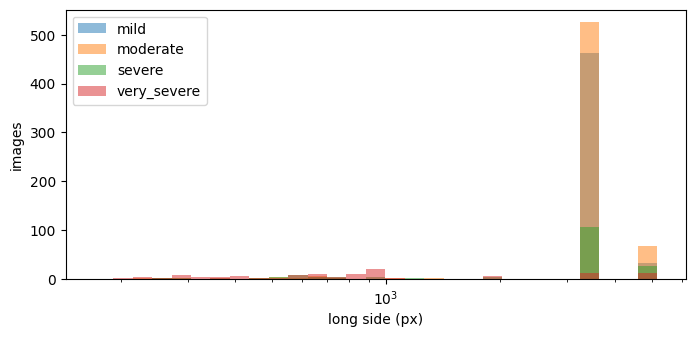

,count,mean,std,min,25%,50%,75%,max
severity,,,,,,,,
mild,513.0,3447.0,653.0,259.0,3456.0,3456.0,3456.0,5184.0
moderate,633.0,3429.0,882.0,228.0,3456.0,3456.0,3456.0,5184.0
severe,182.0,2952.0,1451.0,170.0,1920.0,3456.0,3456.0,5184.0
very_severe,129.0,1390.0,1474.0,196.0,433.0,800.0,1600.0,5184.0


In [8]:
long_side = META[["width", "height"]].max(axis=1)
bins = np.logspace(np.log10(long_side.min()), np.log10(long_side.max()), 30)
fig, ax = plt.subplots(figsize=(8, 3.5))
for name in CLASS_NAMES:
    ax.hist(long_side[META["severity"] == name], bins=bins, alpha=0.5, label=name)
ax.set_xscale("log")
ax.set_xlabel("long side (px)")
ax.set_ylabel("images")
ax.legend()
plt.show()
display(long_side.groupby(META["severity"]).describe().reindex(CLASS_NAMES).round(0))

### Samples per Grade

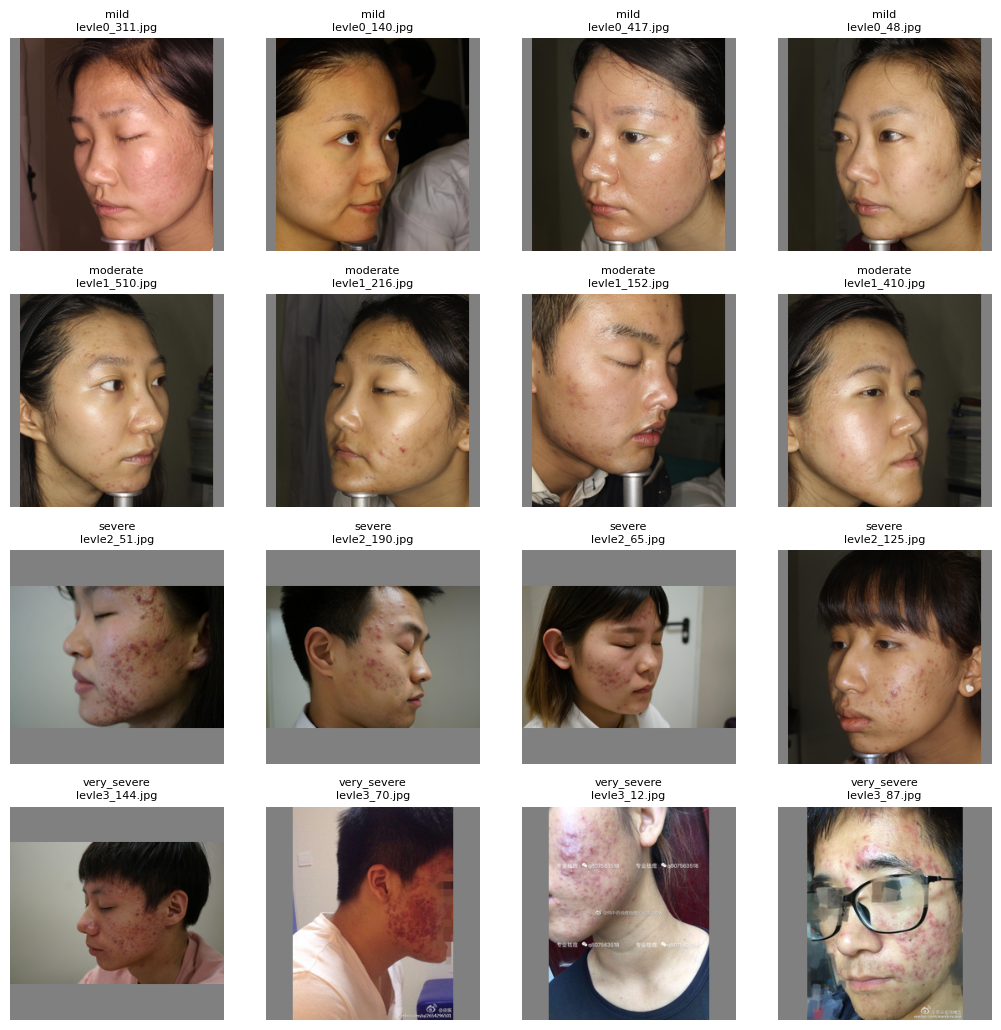

In [9]:
rng = np.random.default_rng(SEED)
picks = [i for level in LABELS for i in rng.choice(np.flatnonzero(META["level"] == level), 4, replace=False)]
show_grid(IMAGES[picks], [f"{META.severity[i]}\n{META.file_name[i]}" for i in picks])

### Duplicates

38 duplicate groups, 76 images, 8 groups with conflicting grades


,copies,grades,files
pixel_hash,,,
2aee54521f26a60c61090e448baca423311180455dc29615e9ff4b2fc0e210f0,2,2,"[levle1_16.jpg, levle2_150.jpg]"
e8941cc0d615dc83205d528bf9c9b9e23baea810993cd72da510d0bc095b4f53,2,2,"[levle1_23.jpg, levle2_153.jpg]"
984afcb40e537489c38c09f5f917c4dadce7a9ca20e51fc904a7445ca2bd055b,2,2,"[levle1_20.jpg, levle2_151.jpg]"
6a0079cad3921651717c58f8d253123e0f01b8983a831164fa3ed71318f0329d,2,2,"[levle0_121.jpg, levle1_504.jpg]"
3d09047f1b317239bddbc2ea2929eb48573d2497d7e95ba298b2702d9cf5852f,2,2,"[levle1_22.jpg, levle2_152.jpg]"
3636c0616610743862f463d695a5160a6bb5f5b71a018f2338951d095cf17240,2,2,"[levle0_185.jpg, levle1_286.jpg]"
d9760d2beeca8e2a9db9d2bddf4d1f2ade6dc24f5dc9fe669f8925765c1c1bb7,2,2,"[levle0_172.jpg, levle1_283.jpg]"
cf28cd34688de49acb970ab7e1244d9f7e1c5c1cf96889d79b68f9f1b4981d73,2,2,"[levle0_120.jpg, levle1_486.jpg]"
30eecde655168948016a3e3220dbaf383968861865ae3796bdf62555bb47e65e,2,1,"[levle1_131.jpg, levle2_128.jpg]"


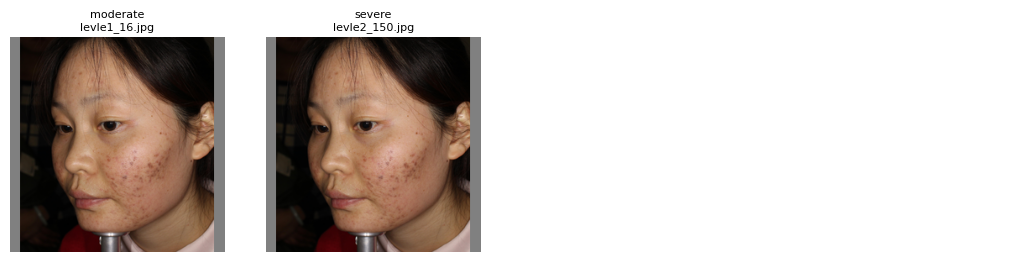

In [10]:
groups = META.groupby("pixel_hash").agg(
    copies=("level", "size"), grades=("level", "nunique"), files=("file_name", list),
)
dups = groups[groups["copies"] > 1].sort_values("grades", ascending=False)
print(f"{len(dups)} duplicate groups, {dups['copies'].sum()} images, "
      f"{(dups['grades'] > 1).sum()} groups with conflicting grades")
display(dups.head(10))

if (dups["grades"] > 1).any():
    rows = META.index[META["pixel_hash"] == dups.index[0]]
    show_grid(IMAGES[rows], [f"{META.severity[i]}\n{META.file_name[i]}" for i in rows])

### Smallest Images

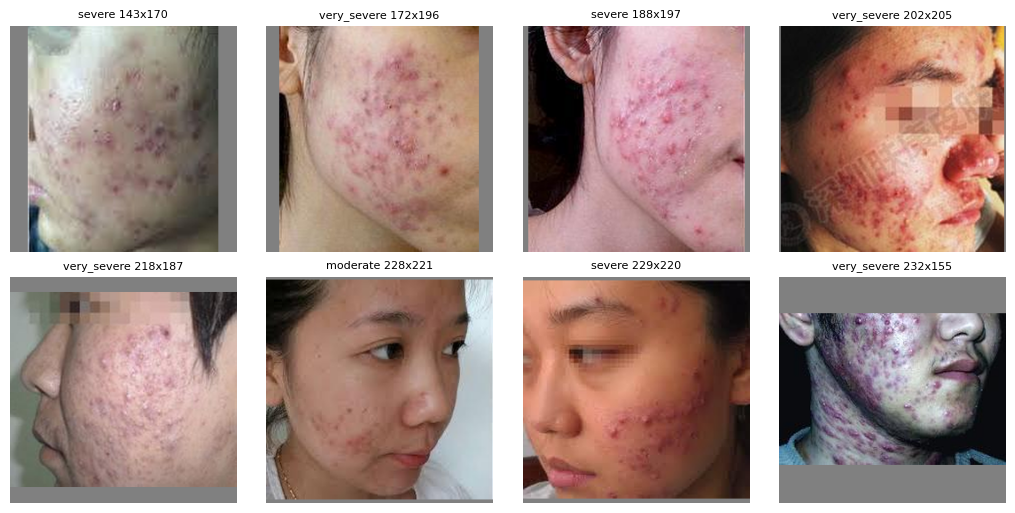

In [11]:
smallest = long_side.nsmallest(8).index
show_grid(IMAGES[smallest], [f"{META.severity[i]} {META.width[i]}x{META.height[i]}" for i in smallest])

### EDA findings

- **how many pics:** 1,457. moderate 633, mild 513, severe 182, very severe 129. so very severe is the smallest group.
- **grades:** grade is basically just the pimple count. mild 1–5, moderate 6–20, severe 21–42, very severe 51–65, no overlap at all.
- **duplicates:** 38 pairs of the exact same pic. 8 of those pairs have different grades (dibuang, label conflict)
- **sizes:** from tiny (170 px) to huge (5,184 px). most pics (1,107) are exactly 3456 px on the long side.

## 3. Cleaning

- drop both duplicate where label conflict.
- drop duplicate.

**Produces:** `DATA`, saved to `CLEAN_PATH`.

In [12]:
def drop_duplicates(meta):
    conflict = meta.groupby("pixel_hash")["level"].transform("nunique") > 1
    repeat = meta.duplicated("pixel_hash", keep="first")
    keep = ~conflict & ~repeat
    removed = meta.loc[~keep, ["file_name", "severity"]].assign(
        reason=np.where(conflict[~keep], "conflicting grades", "repeat copy"))
    return keep.to_numpy(), removed


keep, removed = drop_duplicates(META)
display(removed["reason"].value_counts().to_frame("images"))

clean_meta = META[keep].reset_index(drop=True)
DATA = Data(
    key="acne04_clean",
    images=IMAGES[keep],
    boxes=BOXES[keep],
    y=clean_meta["level"].to_numpy(),
    meta=clean_meta,
    is_test=(clean_meta[FOLD_COLS] == "test").to_numpy(),
)
print(len(DATA.y), "images after cleaning")
display(pd.DataFrame({
    f"fold {k}": np.bincount(DATA.y[DATA.fold(k)[1]], minlength=4) for k in range(N_FOLDS)
}, index=CLASS_NAMES).rename_axis("test images"))

,images
reason,
repeat copy,30
conflicting grades,16


1411 images after cleaning


,fold 0,fold 1,fold 2,fold 3,fold 4
test images,,,,,
mild,102,98,101,101,99
moderate,119,121,124,122,124
severe,35,35,34,36,34
very_severe,26,26,25,26,26


In [13]:
def save_data(data, path):
    np.savez(path, images=data.images, boxes=data.boxes, y=data.y, is_test=data.is_test)
    data.meta.to_csv(path.with_suffix(".csv"), index=False)


def load_data(path):
    arrays = np.load(path)
    return Data("acne04_clean", arrays["images"], arrays["boxes"], arrays["y"],
                pd.read_csv(path.with_suffix(".csv")), arrays["is_test"])


save_data(DATA, CLEAN_PATH)
print("Saved", CLEAN_PATH)

Saved /content/acne04_clean.npz


### Load Saved Data

if you already ran above cell and don't want to run again

In [14]:
DATA = load_data(CLEAN_PATH)
print(len(DATA.y), "images loaded")

1411 images loaded


## 4. Features Extract For Classical MOdel

cell below contain config and function for the following features extraction:

- **HOG**
- **LBP**
- **HSV**

**Produces:** `features(data, blocks)`.

In [15]:
@dataclass(frozen=True)
class HogCfg:
    size: int = 128
    cell: int = 16
    block: int = 2
    orientations: int = 9


@dataclass(frozen=True)
class LbpCfg:
    size: int = 128
    points: int = 8
    radius: int = 1
    grid: int = 4


@dataclass(frozen=True)
class HsvCfg:
    size: int = 128
    bins: tuple = (12, 8, 8)
    grid: int = 2


def at_size(img, box, size):
    if size == img.shape[0]:
        return img, box
    scale = size / img.shape[0]
    small = np.asarray(Image.fromarray(img).resize((size, size), Image.Resampling.LANCZOS))
    return small, tuple(int(round(v * scale)) for v in box)


def grid_cells(region, n):
    return [cell for band in np.array_split(region, n, axis=0) for cell in np.array_split(band, n, axis=1)]


def hog_features(img, box, cfg):
    img, _ = at_size(img, box, cfg.size)
    return hog(rgb2gray(img), orientations=cfg.orientations, pixels_per_cell=(cfg.cell, cfg.cell),
               cells_per_block=(cfg.block, cfg.block), block_norm="L2-Hys", feature_vector=True)


def lbp_features(img, box, cfg):
    img, (x0, y0, x1, y1) = at_size(img, box, cfg.size)
    gray = (rgb2gray(img) * 255).astype(np.uint8)
    codes = local_binary_pattern(gray, cfg.points, cfg.radius, method="uniform")[y0:y1, x0:x1]
    n_bins = cfg.points + 2
    return np.concatenate([
        np.histogram(cell, bins=n_bins, range=(0, n_bins))[0] / max(cell.size, 1)
        for cell in grid_cells(codes, cfg.grid)
    ])


def hsv_features(img, box, cfg):
    img, (x0, y0, x1, y1) = at_size(img, box, cfg.size)
    hsv = rgb2hsv(img[y0:y1, x0:x1])
    hists = []
    for cell in grid_cells(hsv, cfg.grid):
        for channel, bins in enumerate(cfg.bins):
            counts = np.histogram(cell[..., channel], bins=bins, range=(0, 1))[0]
            hists.append(counts / max(counts.sum(), 1))
    return np.concatenate(hists)


EXTRACTORS = {HogCfg: hog_features, LbpCfg: lbp_features, HsvCfg: hsv_features}
CONFIG_TYPES = {cls.__name__: cls for cls in EXTRACTORS}
FEATURE_CACHE = {}


def block_matrix(data, cfg):
    key = (data.key, cfg)
    if data.key is None or key not in FEATURE_CACHE:
        extract = EXTRACTORS[type(cfg)]
        rows = [extract(img, box, cfg) for img, box in
                tqdm(zip(data.images, data.boxes), total=len(data.y), desc=str(cfg), disable=data.key is None)]
        matrix = np.stack(rows).astype(np.float32)
        if data.key is None:
            return matrix
        FEATURE_CACHE[key] = matrix
    return FEATURE_CACHE[key]


def features(data, blocks):
    return np.hstack([block_matrix(data, cfg) for cfg in blocks])

### visualize feature extract

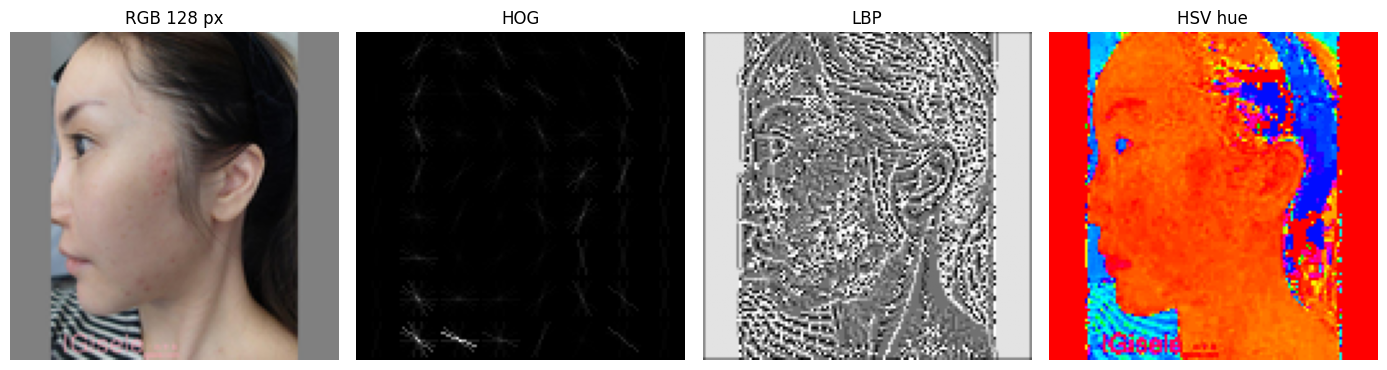

In [16]:
img, box = DATA.images[0], DATA.boxes[0]
small, (x0, y0, x1, y1) = at_size(img, box, 128)
_, hog_view = hog(rgb2gray(small), orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), visualize=True)
lbp_view = local_binary_pattern((rgb2gray(small) * 255).astype(np.uint8), 8, 1, method="uniform")
hue_view = rgb2hsv(small)[..., 0]

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, view, title, cmap in zip(axes, [small, hog_view, lbp_view, hue_view],
                                 ["RGB 128 px", "HOG", "LBP", "HSV hue"], [None, "gray", "gray", "hsv"]):
    ax.imshow(view, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [17]:
# Extract every block used in section 5 now; later cells reuse the cache.
for cfg in [HogCfg(), LbpCfg(), HsvCfg(), HogCfg(size=256), LbpCfg(size=256), HsvCfg(size=256)]:
    print(f"{cfg}: {block_matrix(DATA, cfg).shape[1]} features")

HogCfg(size=128, cell=16, block=2, orientations=9):   0%|          | 0/1411 [00:00<?, ?it/s]

HogCfg(size=128, cell=16, block=2, orientations=9): 1764 features


LbpCfg(size=128, points=8, radius=1, grid=4):   0%|          | 0/1411 [00:00<?, ?it/s]

LbpCfg(size=128, points=8, radius=1, grid=4): 160 features


HsvCfg(size=128, bins=(12, 8, 8), grid=2):   0%|          | 0/1411 [00:00<?, ?it/s]

HsvCfg(size=128, bins=(12, 8, 8), grid=2): 112 features


... (2 outputs left out)

LbpCfg(size=256, points=8, radius=1, grid=4):   0%|          | 0/1411 [00:00<?, ?it/s]

LbpCfg(size=256, points=8, radius=1, grid=4): 160 features


HsvCfg(size=256, bins=(12, 8, 8), grid=2):   0%|          | 0/1411 [00:00<?, ?it/s]

HsvCfg(size=256, bins=(12, 8, 8), grid=2): 112 features


## 5. Models template

- `fit(data, idx)`: trains on the images at `idx` and returns a dict with the trained model
- `predict(fitted, data, idx)`
- `save(fitted, folder)` / `load(folder)`

`run()` saves each model's results per fold to `RESULTS_DIR`

In [18]:
@dataclass(frozen=True)
class ModelSpec:
    name: str
    fit: Callable
    predict: Callable
    save: Callable
    load: Callable


def save_joblib(fitted, folder):
    folder.mkdir(parents=True, exist_ok=True)
    joblib.dump(fitted, folder / "model.joblib")


def load_joblib(folder):
    return joblib.load(folder / "model.joblib")


def cross_validate(spec, data, folds=range(N_FOLDS)):
    fold_rows, pred_rows = [], []
    for k in folds:
        train_idx, test_idx = data.fold(k)
        start = time.time()
        fitted = spec.fit(data, train_idx)
        y_pred = spec.predict(fitted, data, test_idx).argmax(axis=1)
        fold_rows.append({"model": spec.name, "fold": k, **metrics(data.y[test_idx], y_pred),
                          "params": str(fitted.get("params", "")), "seconds": round(time.time() - start, 1)})
        pred_rows.append(pd.DataFrame({"model": spec.name, "fold": k, "index": test_idx,
                                       "y_true": data.y[test_idx], "y_pred": y_pred}))
        print(f"{spec.name} fold {k}: macro-F1 {fold_rows[-1]['macro_f1']:.3f}")
    return {"folds": pd.DataFrame(fold_rows), "predictions": pd.concat(pred_rows, ignore_index=True)}


def run(names, folds=range(N_FOLDS), force=False):
    results = {}
    for name in names:
        folder = RESULTS_DIR / name
        if (folder / "folds.csv").exists() and not force:
            results[name] = {part: pd.read_csv(folder / f"{part}.csv") for part in ["folds", "predictions"]}
            print(f"{name}: loaded saved results")
            continue
        results[name] = cross_validate(MODELS[name], DATA, folds)
        folder.mkdir(parents=True, exist_ok=True)
        for part, frame in results[name].items():
            frame.to_csv(folder / f"{part}.csv", index=False)
    return results

### Majority Baseline

In [19]:
def majority_spec():
    def fit(data, idx):
        return {"grade": int(np.bincount(data.y[idx], minlength=4).argmax())}

    def predict(fitted, data, idx):
        return np.eye(len(CLASS_NAMES))[np.full(len(idx), fitted["grade"])]

    return ModelSpec("majority", fit, predict, save_joblib, load_joblib)

### SVM

In [20]:
SVM_GRID = [
    {"svc__kernel": ["linear"], "svc__C": [0.01, 0.1]},
    {"svc__kernel": ["rbf"], "svc__C": [1, 10, 100], "svc__gamma": ["scale", 1e-4]},
]


def svm_spec(name, blocks, grid=SVM_GRID, inner_folds=3):
    def fit(data, idx):
        search = GridSearchCV(
            Pipeline([("scale", StandardScaler()), ("svc", SVC(class_weight="balanced", break_ties=True))]),
            grid, scoring="f1_macro", n_jobs=-1,
            cv=StratifiedKFold(inner_folds, shuffle=True, random_state=SEED),
        )
        search.fit(features(data, blocks)[idx], data.y[idx])
        return {"model": search.best_estimator_, "params": search.best_params_, "blocks": blocks}

    def predict(fitted, data, idx):
        return fitted["model"].decision_function(features(data, fitted["blocks"])[np.asarray(idx)])

    def save(fitted, folder):
        blocks = [(type(cfg).__name__, asdict(cfg)) for cfg in fitted["blocks"]]
        save_joblib({**fitted, "blocks": blocks}, folder)

    def load(folder):
        fitted = load_joblib(folder)
        return {**fitted, "blocks": [CONFIG_TYPES[kind](**values) for kind, values in fitted["blocks"]]}

    return ModelSpec(name, fit, predict, save, load)

### CNN from scratch

In [21]:
import torch
import torch.nn.functional as F
from torch import nn

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


@dataclass(frozen=True)
class CnnCfg:
    size: int = 256
    widths: tuple = (32, 64, 128, 256, 256)
    epochs: int = 40
    batch: int = 32
    lr: float = 1e-3
    weight_decay: float = 1e-4
    dropout: float = 0.3


def small_cnn(cfg):
    layers, channels = [], 3
    for width in cfg.widths:
        layers += [
            nn.Conv2d(channels, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU(inplace=True),
            nn.Conv2d(width, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        ]
        channels = width
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(cfg.dropout),
                         nn.Linear(channels, len(CLASS_NAMES)))


def to_input(images, size):
    """uint8 (n, H, W, 3) -> float (n, 3, size, size), scaled so the gray padding is about 0."""
    x = images.permute(0, 3, 1, 2).float().div(255).sub(0.5).div(0.25)
    if x.shape[-1] != size:
        x = F.interpolate(x, size=(size, size), mode="bilinear", antialias=True, align_corners=False)
    return x


def augment(x):
    """Random horizontal flip, zoom 0.9-1.1 and shift up to 10%, different for every image."""
    n = len(x)
    scale = torch.empty(n, device=x.device).uniform_(0.9, 1.1)
    flip = torch.where(torch.rand(n, device=x.device) < 0.5, -1.0, 1.0)
    theta = torch.zeros(n, 2, 3, device=x.device)
    theta[:, 0, 0], theta[:, 1, 1] = scale * flip, scale
    theta[:, :, 2] = torch.empty(n, 2, device=x.device).uniform_(-0.1, 0.1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, padding_mode="zeros", align_corners=False)


def cnn_spec(name, cfg=CnnCfg()):
    def fit(data, idx, watch_idx=None):
        """`watch_idx` only records per-epoch scores on those images for the curves; training never uses them."""
        torch.manual_seed(SEED)
        images = torch.from_numpy(data.images[idx]).to(DEVICE)
        y = torch.from_numpy(data.y[idx]).long().to(DEVICE)
        counts = np.bincount(data.y[idx], minlength=len(CLASS_NAMES))
        weights = torch.tensor(len(idx) / (len(counts) * counts), dtype=torch.float32, device=DEVICE)
        model = small_cnn(cfg).to(DEVICE)
        optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
        steps_per_epoch = int(np.ceil(len(idx) / cfg.batch))
        schedule = torch.optim.lr_scheduler.OneCycleLR(optimizer, cfg.lr, total_steps=cfg.epochs * steps_per_epoch)
        history = []
        for epoch in tqdm(range(cfg.epochs), desc=name, leave=False):
            model.train()
            total, lr = torch.zeros((), device=DEVICE), schedule.get_last_lr()[0]
            for batch in torch.randperm(len(idx), device=DEVICE).split(cfg.batch):
                with torch.autocast(DEVICE, enabled=False):
                    loss = F.cross_entropy(model(augment(to_input(images[batch], cfg.size))), y[batch], weight=weights)
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
                schedule.step()
                total += loss.detach() * len(batch)
            row = {"epoch": epoch + 1, "lr": lr, "train_loss": total.item() / len(idx)}
            if watch_idx is not None:
                scores = torch.from_numpy(predict({"model": model, "cfg": cfg}, data, watch_idx))
                y_watch = torch.from_numpy(data.y[watch_idx]).long()
                row["watch_loss"] = F.nll_loss(scores.clamp_min(1e-8).log(), y_watch, weight=weights.cpu()).item()
                row["watch_macro_f1"] = f1_score(y_watch, scores.argmax(1), labels=LABELS, average="macro", zero_division=0)
            history.append(row)
        return {"model": model.eval(), "cfg": cfg, "params": "fixed", "history": pd.DataFrame(history)}

    @torch.no_grad()
    def predict(fitted, data, idx):
        model, size = fitted["model"].eval(), fitted["cfg"].size
        scores = []
        for batch in torch.from_numpy(data.images[np.asarray(idx)]).split(64):
            with torch.autocast(DEVICE, enabled=False):
                scores.append(model(to_input(batch.to(DEVICE), size)).float().softmax(1).cpu())
        return torch.cat(scores).numpy()

    def save(fitted, folder):
        folder.mkdir(parents=True, exist_ok=True)
        torch.save({"state": fitted["model"].state_dict(), "cfg": asdict(fitted["cfg"])}, folder / "model.pt")

    def load(folder):
        saved = torch.load(folder / "model.pt", map_location=DEVICE)
        cfg = CnnCfg(**saved["cfg"])
        model = small_cnn(cfg).to(DEVICE)
        model.load_state_dict(saved["state"])
        return {"model": model.eval(), "cfg": cfg, "params": "fixed"}

    return ModelSpec(name, fit, predict, save, load)


print("CNN device:", DEVICE)

CNN device: cuda


### Model Registry

In [22]:
HOG, LBP, HSV = HogCfg(), LbpCfg(), HsvCfg()
HOG256, LBP256, HSV256 = HogCfg(size=256), LbpCfg(size=256), HsvCfg(size=256)

MODELS = {
    "majority": majority_spec(),
    "svm_hog_lbp": svm_spec("svm_hog_lbp", [HOG, LBP]),
    "svm_hog_lbp_hsv": svm_spec("svm_hog_lbp_hsv", [HOG, LBP, HSV]),
    "cnn_scratch": cnn_spec("cnn_scratch"),
}

In [23]:
RUN = list(MODELS)
RESULTS = run(RUN)

majority fold 0: macro-F1 0.148
majority fold 1: macro-F1 0.151
majority fold 2: macro-F1 0.152
majority fold 3: macro-F1 0.150
majority fold 4: macro-F1 0.152
svm_hog_lbp fold 0: macro-F1 0.527
svm_hog_lbp fold 1: macro-F1 0.494
svm_hog_lbp fold 2: macro-F1 0.553
svm_hog_lbp fold 3: macro-F1 0.563
svm_hog_lbp fold 4: macro-F1 0.456
svm_hog_lbp_hsv fold 0: macro-F1 0.521
svm_hog_lbp_hsv fold 1: macro-F1 0.532
svm_hog_lbp_hsv fold 2: macro-F1 0.570
svm_hog_lbp_hsv fold 3: macro-F1 0.517
svm_hog_lbp_hsv fold 4: macro-F1 0.449


cnn_scratch:   0%|          | 0/40 [00:00<?, ?it/s]

cnn_scratch fold 0: macro-F1 0.772


cnn_scratch:   0%|          | 0/40 [00:00<?, ?it/s]

cnn_scratch fold 1: macro-F1 0.758


cnn_scratch:   0%|          | 0/40 [00:00<?, ?it/s]

cnn_scratch fold 2: macro-F1 0.717


cnn_scratch:   0%|          | 0/40 [00:00<?, ?it/s]

cnn_scratch fold 3: macro-F1 0.705


cnn_scratch:   0%|          | 0/40 [00:00<?, ?it/s]

cnn_scratch fold 4: macro-F1 0.696


## 6. Model Comparison

Every table uses only the folds that all compared models have. Differences smaller than the fold-to-fold spread are not evidence.

In [24]:
SCORES = ["accuracy", "macro_f1", "balanced_accuracy", "qwk", "mae"]


def shared_folds(results, names):
    return sorted(set.intersection(*(set(results[n]["folds"]["fold"]) for n in names)))


def summarize(results, names=None):
    names = names or list(results)
    folds = shared_folds(results, names)
    rows = pd.concat([results[n]["folds"] for n in names])
    rows = rows[rows["fold"].isin(folds)]
    agg = rows.groupby("model")[SCORES].agg(["mean", "std"])
    table = pd.DataFrame({s: agg[(s, "mean")].map("{:.3f}".format) + " ± " + agg[(s, "std")].map("{:.3f}".format)
                          for s in SCORES})
    print("Folds used:", folds)
    return table.loc[agg[("macro_f1", "mean")].sort_values(ascending=False).index]


display(summarize(RESULTS))

Folds used: [0, 1, 2, 3, 4]


,accuracy,macro_f1,balanced_accuracy,qwk,mae
model,,,,,
cnn_scratch,0.758 ± 0.030,0.730 ± 0.033,0.742 ± 0.034,0.850 ± 0.027,0.249 ± 0.036
svm_hog_lbp,0.554 ± 0.042,0.519 ± 0.044,0.517 ± 0.047,0.604 ± 0.056,0.510 ± 0.056
svm_hog_lbp_hsv,0.557 ± 0.036,0.518 ± 0.044,0.516 ± 0.051,0.611 ± 0.073,0.504 ± 0.056
majority,0.431 ± 0.007,0.151 ± 0.002,0.250 ± 0.000,0.000 ± 0.000,0.660 ± 0.008


In [25]:
recall_cols = [f"recall_{c}" for c in CLASS_NAMES]
recalls = pd.concat([RESULTS[n]["folds"] for n in RESULTS]).groupby("model")[recall_cols].mean()
display(recalls.round(3))

,recall_mild,recall_moderate,recall_severe,recall_very_severe
model,,,,
cnn_scratch,0.918,0.664,0.627,0.759
majority,0.000,1.000,0.000,0.000
svm_hog_lbp,0.589,0.589,0.317,0.574
svm_hog_lbp_hsv,0.591,0.603,0.264,0.606


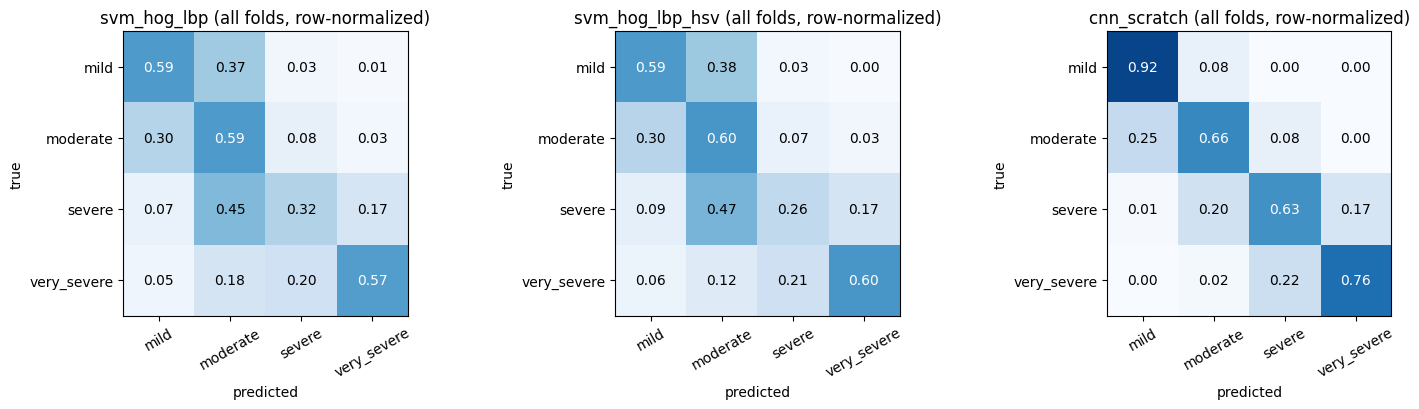

In [26]:
COMPARE = ["svm_hog_lbp", "svm_hog_lbp_hsv", "cnn_scratch"]
fig, axes = plt.subplots(1, len(COMPARE), figsize=(5 * len(COMPARE), 4.2), squeeze=False)
for ax, name in zip(axes.flat, COMPARE):
    preds = RESULTS[name]["predictions"]
    cm = confusion_matrix(preds["y_true"], preds["y_pred"], labels=LABELS, normalize="true")
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    for (r, c), v in np.ndenumerate(cm):
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.5 else "black")
    ax.set_xticks(LABELS, CLASS_NAMES, rotation=30)
    ax.set_yticks(LABELS, CLASS_NAMES)
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(f"{name} (all folds, row-normalized)")
plt.tight_layout()
plt.show()

In [27]:
from sklearn.metrics import classification_report

for name in COMPARE:
    preds = RESULTS[name]["predictions"]
    print(f"== {name}")
    print(classification_report(preds["y_true"], preds["y_pred"], labels=LABELS, target_names=CLASS_NAMES,
                                digits=3, zero_division=0))

== svm_hog_lbp
              precision    recall  f1-score   support

        mild      0.592     0.589     0.591       501
    moderate      0.557     0.589     0.572       610
      severe      0.377     0.316     0.344       174
 very_severe      0.592     0.574     0.583       129

    accuracy                          0.554      1414
   macro avg      0.529     0.517     0.522      1414
weighted avg      0.550     0.554     0.552      1414

== svm_hog_lbp_hsv
              precision    recall  f1-score   support

        mild      0.591     0.591     0.591       501
    moderate      0.562     0.603     0.582       610
      severe      0.359     0.264     0.305       174
 very_severe      0.600     0.605     0.602       129

    accuracy                          0.557      1414
   macro avg      0.528     0.516     0.520      1414
weighted avg      0.551     0.557     0.553      1414

== cnn_scratch
              precision    recall  f1-score   support

        mild      0.747   

# TODO
- acutally verify the model is good on unknown data
- cnn accuracy is actually suspicious
- cnn might actually remembering faces and or color
- for current dataset i think more preprocessing is needed, like croopping to cheeks only and or color standarizaiton
- randomization of color and lighting during training might also helps
- can also try pretrained model, might generalize to unknown image better
- anything here not be trusted yet

## 7. Predict

In [28]:
MODEL_NAME = "cnn_scratch"
FINAL = {}


def final_model(name, refit=False):
    folder = EXPORT_DIR / name
    if name not in FINAL or refit:
        if folder.exists() and not refit:
            FINAL[name] = MODELS[name].load(folder)
        else:
            FINAL[name] = MODELS[name].fit(DATA, np.arange(len(DATA.y)))
    return FINAL[name]


def photo_data(img):
    arr, box = letterbox(upright(img))
    return Data(None, arr[None], np.array([box]), np.array([-1]), pd.DataFrame(), np.zeros((1, 0), bool))


def show_prediction(img, scores, title):
    fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
    left.imshow(img)
    left.axis("off")
    left.set_title(title, fontsize=9)
    right.barh(CLASS_NAMES, scores, color=["tab:blue" if i == scores.argmax() else "lightgray" for i in LABELS])
    right.invert_yaxis()
    right.set_xlabel("score")
    plt.tight_layout()
    plt.show()

### An ACNE04 Image

Uses the cross-validated prediction, made by the fold model that never saw this image.

#1314 levle3_133.jpg: true very_severe, predicted very_severe (fold 4)


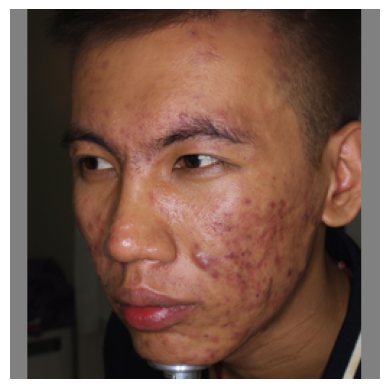

In [29]:
# A random prediction from images in the dataset
row = RESULTS[MODEL_NAME]["predictions"].sample(1).iloc[0]
IMAGE_INDEX = int(row["index"])
print(f"#{IMAGE_INDEX} {DATA.meta.file_name[IMAGE_INDEX]}: true {CLASS_NAMES[row.y_true]}, "
      f"predicted {CLASS_NAMES[row.y_pred]} (fold {row.fold})")
plt.imshow(DATA.images[IMAGE_INDEX])
plt.axis("off")
plt.show()

### Your Own Photo

Set `IMAGE_PATH`, or leave it `None` to upload in Colab. ACNE04 has no clear-skin class, so every photo gets one of the four grades.

In [30]:
IMAGE_PATH = None  # or set to a path to an image file, e.g. "/path/to/image.png"

if IMAGE_PATH is None:
    print("set IMAGE_PATH first man")
else:
    name, photo = Path(IMAGE_PATH).name, Image.open(IMAGE_PATH)

if IMAGE_PATH is not None:
    data = photo_data(photo)
    scores = MODELS[MODEL_NAME].predict(final_model(MODEL_NAME), data, [0])[0]
    show_prediction(data.images[0], scores, f"{name}\n{MODEL_NAME}: {CLASS_NAMES[scores.argmax()]}")

set IMAGE_PATH first man


## 8. Export

Saves each model to `EXPORT_DIR/<name>/` with `info.json` (settings, cross-validated scores) and zips the folder.

In [31]:
EXPORT = ["svm_hog_lbp", "svm_hog_lbp_hsv"]

for name in EXPORT:
    folder = EXPORT_DIR / name
    fitted = final_model(name)
    MODELS[name].save(fitted, folder)
    cv = RESULTS[name]["folds"][SCORES].agg(["mean", "std"]).round(4).to_dict() if name in RESULTS else None
    info = {
        "model": name,
        "class_names": CLASS_NAMES,
        "base_size": BASE_SIZE,
        "params": str(fitted.get("params", "")),
        "trained_on_images": int(len(DATA.y)),
        "cross_validation": cv,
        "exported": datetime.now().isoformat(timespec="seconds"),
    }
    (folder / "info.json").write_text(json.dumps(info, indent=2))
    print("Saved", folder)

archive = shutil.make_archive(str(EXPORT_DIR), "zip", EXPORT_DIR)
print("Zip:", archive)

Saved /content/exports/svm_hog_lbp
Saved /content/exports/svm_hog_lbp_hsv
Zip: /content/exports.zip


In [32]:
# Optional: download the zip from Colab.
# from google.colab import files
# files.download(archive)